In [1]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [55]:
import os
import json
import random
import torch
import matplotlib.pyplot as plt
import torch.nn as nn
import numpy as np
import pandas as pd
import torch.nn.functional as F

from typing import Dict, Tuple, Optional
from datetime import datetime
from torch.utils.data import Dataset, DataLoader

In [3]:
# Canonical paths (match Notebook 08)
base_dir = "/content/drive/MyDrive/Final_Year_Project/Implementation/datasets/AntM2C_10M"
preprocessed_dir = f"{base_dir}/AntM2C_preprocessed"
checkpoints_dir = f"{base_dir}/checkpoints"
splits_dir = f"{preprocessed_dir}/splits"
split_features_dir = f"{preprocessed_dir}/split_features"

results_dir = f"{base_dir}/eval_results"
os.makedirs(results_dir, exist_ok=True)

In [4]:
# Artifact paths (Notebook 08 actual filenames)
model_ckpt_path = os.path.join(checkpoints_dir, "coldfusionx_model_epoch3.pt")
fusion_config_path = os.path.join(checkpoints_dir, "fusion_config.json")
meta_config_path = os.path.join(checkpoints_dir, "meta_config.json")
training_meta_path = os.path.join(checkpoints_dir, "training_meta_epoch3.json")

test_idx_path = os.path.join(splits_dir, "test_idx.npy")
val_idx_path = os.path.join(splits_dir, "val_idx.npy")

In [5]:
# Existence checks
required_paths = {
    "base_dir": base_dir,
    "preprocessed_dir": preprocessed_dir,
    "checkpoints_dir": checkpoints_dir,
    "splits_dir": splits_dir,
    "split_features_dir": split_features_dir,
    "results_dir": results_dir,
    "model_ckpt_path": model_ckpt_path,
    "fusion_config_path": fusion_config_path,
    "meta_config_path": meta_config_path,
    "training_meta_path": training_meta_path,
    "test_idx_path": test_idx_path,
}

In [6]:
missing = [k for k, p in required_paths.items() if not os.path.exists(p)]
if missing:
    print("Missing required paths:")
    for k in missing:
        print(f" - {k}: {required_paths[k]}")
    raise FileNotFoundError("One or more required files/folders are missing. Fix paths before continuing.")

In [7]:
# Reproducibility
SEED = 42           # consistent with Notebook 08
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

In [8]:
device = "cuda" if torch.cuda.is_available() else "cpu"

In [9]:
# Determinism flags (for evaluation reproducibility)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

In [10]:
# Load configs
with open(fusion_config_path, "r") as f:
    fusion_config = json.load(f)

with open(meta_config_path, "r") as f:
    meta_config = json.load(f)

with open(training_meta_path, "r") as f:
    training_meta = json.load(f)

In [11]:
# Load split indices
test_idx = np.load(test_idx_path)
val_idx = np.load(val_idx_path) if os.path.exists(val_idx_path) else None

In [12]:
# Extract key values (safe getters)
d_model = fusion_config.get("d_model", fusion_config.get("D_MODEL", None))
fewshot_n = meta_config.get("FEWSHOT_N", meta_config.get("fewshot_n", None))
num_scenes = meta_config.get("NUM_SCENES", meta_config.get("num_scenes", None))

batch_size = training_meta.get("batch_size", training_meta.get("BATCH_SIZE", None))

In [13]:
print("--- Key Config Values ---")
print("d_model:", d_model)
print("FEWSHOT_N:", fewshot_n)
print("num_scenes:", num_scenes)
print("batch_size (from training_meta):", batch_size)

print("\n--- Split Sizes ---")
print("test_idx:", len(test_idx))
print("val_idx:", len(val_idx) if val_idx is not None else "N/A (missing or not loaded)")

print("\n--- Paths ---")
for k, p in required_paths.items():
    print(f"{k}: {p}")

--- Key Config Values ---
d_model: 256
FEWSHOT_N: 10
num_scenes: None
batch_size (from training_meta): 4096

--- Split Sizes ---
test_idx: 373033
val_idx: 373033

--- Paths ---
base_dir: /content/drive/MyDrive/Final_Year_Project/Implementation/datasets/AntM2C_10M
preprocessed_dir: /content/drive/MyDrive/Final_Year_Project/Implementation/datasets/AntM2C_10M/AntM2C_preprocessed
checkpoints_dir: /content/drive/MyDrive/Final_Year_Project/Implementation/datasets/AntM2C_10M/checkpoints
splits_dir: /content/drive/MyDrive/Final_Year_Project/Implementation/datasets/AntM2C_10M/AntM2C_preprocessed/splits
split_features_dir: /content/drive/MyDrive/Final_Year_Project/Implementation/datasets/AntM2C_10M/AntM2C_preprocessed/split_features
results_dir: /content/drive/MyDrive/Final_Year_Project/Implementation/datasets/AntM2C_10M/eval_results
model_ckpt_path: /content/drive/MyDrive/Final_Year_Project/Implementation/datasets/AntM2C_10M/checkpoints/coldfusionx_model_epoch3.pt
fusion_config_path: /content/d

### Load Row-Aligned Evaluation Artifacts + Assert Alignment

In [14]:
# Row-aligned artifacts (interaction-level)
df_id_path = os.path.join(split_features_dir, "df_id_encoded.pkl")
df_processed_path = os.path.join(preprocessed_dir, "df_processed.pkl")  # used for labels
text_embeddings_path = os.path.join(preprocessed_dir, "text_embeddings.npy")
time_features_path = os.path.join(preprocessed_dir, "time_features_final.pt")

In [15]:
# Item-level artifacts (lookup by item_id_idx)
image_embeddings_path = os.path.join(base_dir, "image_embeddings_vit_base_aligned.pt")
image_missing_mask_path = os.path.join(base_dir, "image_missing_mask.pt")

In [16]:
# Existence checks (fail early)
required_step1 = {
    "df_id_path": df_id_path,
    "df_processed_path": df_processed_path,
    "text_embeddings_path": text_embeddings_path,
    "time_features_path": time_features_path,
    "image_embeddings_path": image_embeddings_path,
    "image_missing_mask_path": image_missing_mask_path,
}

In [17]:
missing_step1 = [k for k, p in required_step1.items() if not os.path.exists(p)]
if missing_step1:
    print("Missing artifacts:")
    for k in missing_step1:
        print(f" - {k}: {required_step1[k]}")
    raise FileNotFoundError("One or more Step 1 artifacts are missing. Fix paths before continuing.")

#### Load Artifacts (df_id, text memmap, time features, image tables, labels)

In [18]:
# Load df_id_encoded.pkl
df_id = pd.read_pickle(df_id_path)

In [19]:
# Load text embeddings (memmap)
text_memmap = np.load(text_embeddings_path, mmap_mode="r")

In [20]:
# Load time features
time_features = torch.load(time_features_path, map_location="cpu")

In [21]:
# Load item-level image embedding table + missing mask
image_embeddings = torch.load(image_embeddings_path, map_location="cpu")
image_missing_mask = torch.load(image_missing_mask_path, map_location="cpu")

In [22]:
# Load labels (same approach as Notebook 08: detect column)
df_processed = pd.read_pickle(df_processed_path)

In [23]:
label_col = "label"
labels = df_processed[label_col].to_numpy(dtype=np.float32)

#### Load Train Split + Build Train-Only Item Counts

In [24]:
train_idx_path = os.path.join(splits_dir, "train_idx.npy")
train_idx = np.load(train_idx_path)

In [25]:
# Ensure indices are integer type
train_idx = train_idx.astype(np.int64)

# FEWSHOT_N from meta_config (Notebook 08 standard)
FEWSHOT_N = int(meta_config["FEWSHOT_N"])

# Derive num_items from df_id (already verified)
num_items = int(df_id["item_id_idx"].max()) + 1

In [26]:
# Extract train items and compute bincount (train-only exposure counts)
train_items = df_id.iloc[train_idx]["item_id_idx"].to_numpy(dtype=np.int64)
item_train_count = np.bincount(train_items, minlength=num_items).astype(np.int64)

# Sanity checks
assert item_train_count.shape[0] == num_items, "item_train_count length mismatch with num_items"
assert item_train_count.min() >= 0, "Negative counts detected (unexpected)"

In [27]:
print("--- Train-only item counts computed. ---")
print("train_idx:", len(train_idx))
print("num_items:", num_items)
print("FEWSHOT_N:", FEWSHOT_N)

--- Train-only item counts computed. ---
train_idx: 2984263
num_items: 59142
FEWSHOT_N: 10


#### Summary Stats + Cold-Item Percentage

In [28]:
# Summary statistics
min_count = int(item_train_count.min())
max_count = int(item_train_count.max())
mean_count = float(item_train_count.mean())
median_count = float(np.median(item_train_count))

In [29]:
# How many items are "cold" by the few-shot definition (<= FEWSHOT_N exposures in train)
cold_items_mask = item_train_count <= FEWSHOT_N
num_cold_items = int(cold_items_mask.sum())
pct_cold_items = 100.0 * num_cold_items / num_items

# How many items are completely unseen in train (count == 0)
num_unseen_items = int((item_train_count == 0).sum())
pct_unseen_items = 100.0 * num_unseen_items / num_items

In [30]:
# Distribution slices (useful for sanity checks)
num_1_5 = int(((item_train_count >= 1) & (item_train_count <= 5)).sum())
num_6_10 = int(((item_train_count >= 6) & (item_train_count <= 10)).sum())
num_11_50 = int(((item_train_count >= 11) & (item_train_count <= 50)).sum())
num_gt_50 = int((item_train_count > 50).sum())

In [31]:
print("--- Train-only Count Summary ---")
print(f"Items (num_items): {num_items:,}")
print(f"Train interactions: {len(train_idx):,}")
print(f"Count stats: min={min_count}, median={median_count:.2f}, mean={mean_count:.2f}, max={max_count}")

print("\n--- Cold definition (train-only) ---")
print(f"FEWSHOT_N: {FEWSHOT_N}")
print(f"Cold items (count <= {FEWSHOT_N}): {num_cold_items:,} ({pct_cold_items:.2f}%)")
print(f"Unseen items (count == 0): {num_unseen_items:,} ({pct_unseen_items:.2f}%)")

print("\n--- Count buckets (train-only) ---")
print(f"1–5:   {num_1_5:,}")
print(f"6–10:  {num_6_10:,}")
print(f"11–50: {num_11_50:,}")
print(f">50:   {num_gt_50:,}")

--- Train-only Count Summary ---
Items (num_items): 59,142
Train interactions: 2,984,263
Count stats: min=0, median=2.00, mean=50.46, max=401813

--- Cold definition (train-only) ---
FEWSHOT_N: 10
Cold items (count <= 10): 44,959 (76.02%)
Unseen items (count == 0): 4,493 (7.60%)

--- Count buckets (train-only) ---
1–5:   35,065
6–10:  5,401
11–50: 8,712
>50:   5,471


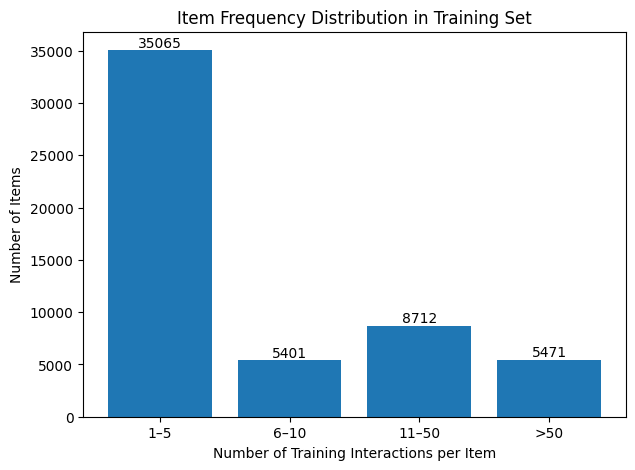

In [32]:
# Distribution values
labels_dist = ['1–5', '6–10', '11–50', '>50']
counts = [num_1_5, num_6_10, num_11_50, num_gt_50]

plt.figure(figsize=(7, 5))
plt.bar(labels_dist, counts)
plt.xlabel("Number of Training Interactions per Item")
plt.ylabel("Number of Items")
plt.title("Item Frequency Distribution in Training Set")

# annotate counts on bars
for i, v in enumerate(counts):
    plt.text(i, v, str(v), ha='center', va='bottom')

plt.show()

In [33]:
# ensure splits are disjoint (not overlapping)
test_set = set(test_idx.tolist())
train_set = set(train_idx.tolist())
val_set = set(val_idx.tolist()) if val_idx is not None else set()

overlap_train_test = len(train_set.intersection(test_set))
overlap_train_val = len(train_set.intersection(val_set))
overlap_val_test = len(val_set.intersection(test_set)) if val_idx is not None else 0

print("--- Split Integrity Check ---")
print("Overlap train ∩ test:", overlap_train_test)
print("Overlap train ∩ val :", overlap_train_val)
print("Overlap val ∩ test  :", overlap_val_test)

if overlap_train_test == 0 and overlap_train_val == 0 and overlap_val_test == 0:
    print("\nSplits appear disjoint.")
else:
    print("\nSplits overlap detected. This can invalidate cold_mask and evaluation.")

--- Split Integrity Check ---
Overlap train ∩ test: 0
Overlap train ∩ val : 0
Overlap val ∩ test  : 0

Splits appear disjoint.


#### Build Test Dataset + DataLoader (Evaluation Mode)

In [34]:
# test_idx already loaded, double check dtype
test_idx = test_idx.astype(np.int64)

# Build item_is_fewshot using TRAIN-only counts (Notebook 08 logic)
# Cold definition: count <= FEWSHOT_N
item_is_fewshot = torch.tensor(item_train_count <= FEWSHOT_N, dtype=torch.bool)

print("item_is_fewshot:", item_is_fewshot.shape, "| cold_items:", int(item_is_fewshot.sum()))
print("test_idx:", test_idx.shape, "| example idx:", int(test_idx[0]))

item_is_fewshot: torch.Size([59142]) | cold_items: 44959
test_idx: (373033,) | example idx: 2296852


In [35]:
# This class was already introduced in previous notebooks (copy pasting it here for reuse)
class CTRDataset(Dataset):
    """
    Row-aligned CTR dataset.

    Returns:
      user_id_idx: LongTensor ()
      item_id_idx: LongTensor ()
      scene_idx:   LongTensor ()
      text_vec:    FloatTensor (1536)
      time_vec:    FloatTensor (5)
      image_vec:   FloatTensor (768) (zero if missing)
      label:       FloatTensor ()
      cold_mask:   BoolTensor ()
    """
    def __init__(
        self,
        row_indices: np.ndarray,
        df_id: pd.DataFrame,
        text_embeddings_memmap: np.ndarray,
        time_features: torch.Tensor,
        image_embeddings: torch.Tensor,
        image_missing_mask: torch.Tensor,
        labels: np.ndarray,
        item_is_fewshot: torch.Tensor,
        item_train_count: np.ndarray,   # NEW
    ):
        self.row_indices = row_indices.astype(np.int64)
        self.df_id = df_id
        self.text_mem = text_embeddings_memmap
        self.time = time_features
        self.image = image_embeddings
        self.img_missing = image_missing_mask.bool()
        self.labels = labels
        self.item_is_fewshot = item_is_fewshot
        self.item_train_count = item_train_count

        self.text_dim = self.text_mem.shape[1]
        self.time_dim = self.time.shape[1]
        self.image_dim = self.image.shape[1]

    def __len__(self):
        return len(self.row_indices)

    def __getitem__(self, i: int):
        row_idx = int(self.row_indices[i])

        row = self.df_id.iloc[row_idx]
        user_idx = int(row["user_id_idx"])
        item_idx = int(row["item_id_idx"])
        scene_idx = int(row["scene_idx"])

        # Interaction-level features
        text_vec = torch.from_numpy(self.text_mem[row_idx].copy()).float()
        time_vec = self.time[row_idx].float()                                 # (5,)

        # Item-level image embedding (zero if missing)
        if bool(self.img_missing[item_idx].item()):
            image_vec = torch.zeros(self.image_dim, dtype=torch.float32)
        else:
            image_vec = self.image[item_idx].float()                          # (768,)

        # Label
        y = float(self.labels[row_idx])
        label = torch.tensor(y, dtype=torch.float32)

        # Frequency count (TRAIN exposure count for this item)
        item_count = int(self.item_train_count[item_idx])
        item_count = torch.tensor(item_count, dtype=torch.long)

        # Cold mask (keep for reporting/metrics; no longer required for blending)
        cold_mask = bool(self.item_is_fewshot[item_idx])
        # Frequency count (TRAIN exposure count for this item)
        item_count = int(self.item_train_count[item_idx])

        return {
            "row_idx": torch.tensor(row_idx, dtype=torch.long),
            "user_idx": torch.tensor(user_idx, dtype=torch.long),
            "item_idx": torch.tensor(item_idx, dtype=torch.long),
            "scene_idx": torch.tensor(scene_idx, dtype=torch.long),
            "text_vec": text_vec,
            "time_vec": time_vec,
            "image_vec": image_vec,
            "label": label,
            "cold_mask": torch.tensor(cold_mask, dtype=torch.bool),
            "item_count": torch.tensor(item_count, dtype=torch.long),   # NEW
        }

In [36]:
# Create test dataset (evaluation mode)
test_dataset = CTRDataset(
    row_indices=test_idx,
    df_id=df_id,
    text_embeddings_memmap=text_memmap,
    time_features=time_features if torch.is_tensor(time_features) else torch.tensor(time_features),
    image_embeddings=image_embeddings,
    image_missing_mask=image_missing_mask,
    labels= labels,
    item_is_fewshot=item_is_fewshot,
    item_train_count=item_train_count,
)

In [37]:
# Create DataLoader (deterministic)
# Use training batch_size as a starting point (4096), but CPU may prefer smaller batches.
eval_batch_size = int(training_meta.get("batch_size", 4096))

In [38]:
# If CPU evaluation is slow or memory tight
if device == "cpu":
    eval_batch_size = min(eval_batch_size, 1024)

In [39]:
test_loader = DataLoader(
    test_dataset,
    batch_size=eval_batch_size,
    shuffle=False,
    pin_memory=(device == "cuda"),
    drop_last=False,
)

print("test_dataset length:", len(test_dataset))
print("test_loader batch_size:", eval_batch_size)

test_dataset length: 373033
test_loader batch_size: 4096


In [40]:
# One-batch sanity check
batch = next(iter(test_loader))

In [41]:
# Shapes
print("--- One-batch check ---")
for k in ["user_idx", "item_idx", "scene_idx", "text_vec", "time_vec", "image_vec", "label", "cold_mask", "item_count"]:
    v = batch[k]
    if torch.is_tensor(v):
        print(f"{k:10s} shape={tuple(v.shape)} dtype={v.dtype}")
    else:
        print(f"{k:10s} type={type(v)}")

--- One-batch check ---
user_idx   shape=(4096,) dtype=torch.int64
item_idx   shape=(4096,) dtype=torch.int64
scene_idx  shape=(4096,) dtype=torch.int64
text_vec   shape=(4096, 1536) dtype=torch.float32
time_vec   shape=(4096, 5) dtype=torch.float32
image_vec  shape=(4096, 768) dtype=torch.float32
label      shape=(4096,) dtype=torch.float32
cold_mask  shape=(4096,) dtype=torch.bool
item_count shape=(4096,) dtype=torch.int64


In [42]:
# Rates
cold_rate = float(batch["cold_mask"].float().mean())
pos_rate = float(batch["label"].float().mean())

print("Batch cold rate:", cold_rate)
print("Batch positive rate:", pos_rate)

Batch cold rate: 0.042236328125
Batch positive rate: 0.32861328125


In [43]:
# Quick correctness checks
assert batch["text_vec"].shape[1] == 1536, "text_vec dim mismatch"
assert batch["time_vec"].shape[1] == 5, "time_vec dim mismatch"
assert batch["image_vec"].shape[1] == 768, "image_vec dim mismatch"

#### Rebuild Model and Load Checkpoint
(Copy pasting from the implementation in Notebook 08)

In [48]:
# from Notebook 06
class ModalityAttentionFusion(nn.Module):
    """
    Projects {id, text, image, time} into a shared d_model space and applies
    per-sample attention over modalities.

    Forward inputs:
      id_vec:    (B, id_dim)
      text_vec:  (B, text_dim=1536)
      image_vec: (B, image_dim=768)
      time_vec:  (B, time_dim=5 or Time2Vec dim later)

    Output:
      fused: (B, d_model)

    Diagnostics:
      get_last_attention() returns a dict of attention weights.
    """
    def __init__(
        self,
        id_dim: int,
        text_dim: int,
        image_dim: int,
        time_dim: int,
        d_model: int = 256,
        attn_hidden: int = 128,
        dropout: float = 0.1
    ):
        super().__init__()

        # Projections into shared d_model
        self.proj_id = nn.Sequential(
            nn.Linear(id_dim, d_model),
            nn.ReLU(),
            nn.Dropout(dropout),
        )
        self.proj_text = nn.Sequential(
            nn.Linear(text_dim, d_model),
            nn.ReLU(),
            nn.Dropout(dropout),
        )
        self.proj_image = nn.Sequential(
            nn.Linear(image_dim, d_model),
            nn.ReLU(),
            nn.Dropout(dropout),
        )
        self.proj_time = nn.Sequential(
            nn.Linear(time_dim, d_model),
            nn.ReLU(),
            nn.Dropout(dropout),
        )

        # Attention MLP produces 1 scalar score per modality per sample
        self.attn_mlp = nn.Sequential(
            nn.Linear(d_model, attn_hidden),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(attn_hidden, 1)
        )

        self._last_attention: Optional[Dict[str, torch.Tensor]] = None

    def forward(
        self,
        id_vec: torch.Tensor,
        text_vec: torch.Tensor,
        image_vec: torch.Tensor,
        time_vec: torch.Tensor
    ) -> torch.Tensor:

        # Project each modality to (B, d_model)
        z_id = self.proj_id(id_vec)
        z_text = self.proj_text(text_vec)
        z_image = self.proj_image(image_vec)
        z_time = self.proj_time(time_vec)

        # Stack: (B, M=4, d_model)
        Z = torch.stack([z_id, z_text, z_image, z_time], dim=1)

        # Compute attention logits per modality: (B, 4, 1) -> (B, 4)
        logits = self.attn_mlp(Z).squeeze(-1)

        # Softmax over modalities -> (B, 4)
        attn = F.softmax(logits, dim=1)

        # Weighted sum: (B, 4, 1) * (B, 4, d_model) -> (B, d_model)
        fused = torch.sum(attn.unsqueeze(-1) * Z, dim=1)

        # Save for diagnostics (detach for safe logging)
        self._last_attention = {
            "id": attn[:, 0].detach(),
            "text": attn[:, 1].detach(),
            "image": attn[:, 2].detach(),
            "time": attn[:, 3].detach(),
        }

        return fused

    def get_last_attention(self) -> Optional[Dict[str, torch.Tensor]]:
        return self._last_attention

In [49]:
# from notbook 06
class ScenarioAwareMMoE(nn.Module):
    """
    Scenario-aware Mixture-of-Experts (MMoE).

    Inputs:
      x:        (B, d_model)   fused representation
      scene_idx:(B,)           scenario indices (0..num_scenes-1)

    Outputs:
      y:        (B, hidden_dim) combined expert output

    Diagnostics:
      get_last_gates(): returns gate weights (B, num_experts)
    """
    def __init__(
        self,
        d_model: int,
        hidden_dim: int,
        num_experts: int,
        num_scenes: int,
        gate_embed_dim: int = 16,
        expert_dropout: float = 0.1
    ):
        super().__init__()

        self.d_model = d_model
        self.hidden_dim = hidden_dim
        self.num_experts = num_experts
        self.num_scenes = num_scenes

        # Experts: each expert maps (B, d_model) -> (B, hidden_dim)
        self.experts = nn.ModuleList([
            nn.Sequential(
                nn.Linear(d_model, hidden_dim),
                nn.ReLU(),
                nn.Dropout(expert_dropout),
                nn.Linear(hidden_dim, hidden_dim),
                nn.ReLU(),
                nn.Dropout(expert_dropout),
            )
            for _ in range(num_experts)
        ])

        # Scene embedding used for gating
        self.scene_embed = nn.Embedding(num_scenes, gate_embed_dim)

        # Gate network: conditioned on scene embedding (optionally we can include x too later)
        self.gate = nn.Sequential(
            nn.Linear(gate_embed_dim, gate_embed_dim),
            nn.ReLU(),
            nn.Linear(gate_embed_dim, num_experts)
        )

        self._last_gates: Optional[torch.Tensor] = None

    def forward(self, x: torch.Tensor, scene_idx: torch.Tensor) -> torch.Tensor:
        """
        Args:
            x: (B, d_model)
            scene_idx: (B,)
        Returns:
            y: (B, hidden_dim)
        """
        B = x.size(0)

        # Expert outputs: list of (B, hidden_dim) -> stack -> (B, E, hidden_dim)
        expert_outputs = torch.stack([expert(x) for expert in self.experts], dim=1)

        # Compute gate weights conditioned on scene_idx
        s_emb = self.scene_embed(scene_idx)           # (B, gate_embed_dim)
        gate_logits = self.gate(s_emb)                # (B, num_experts)
        gates = F.softmax(gate_logits, dim=-1)        # (B, num_experts)

        # Combine experts: (B, E, 1) * (B, E, hidden_dim) -> (B, hidden_dim)
        y = torch.sum(gates.unsqueeze(-1) * expert_outputs, dim=1)

        # Store for diagnostics
        self._last_gates = gates.detach()

        return y

    def get_last_gates(self) -> Optional[torch.Tensor]:
        return self._last_gates

In [50]:
# from notebook 07
class IDEmbeddingLayer(nn.Module):
    """
    Embedding tables for user/item/scene.
    Produces user_emb, item_emb, scene_emb.
    """
    def __init__(self, num_users: int, num_items: int, num_scenes: int,
                 id_dim: int = 256, scene_dim: int = 32, dropout: float = 0.0):
        super().__init__()
        self.user_emb = nn.Embedding(num_users, id_dim)
        self.item_emb = nn.Embedding(num_items, id_dim)
        self.scene_emb = nn.Embedding(num_scenes, scene_dim)

        self.dropout = nn.Dropout(dropout)

    def forward(self, user_idx: torch.Tensor, item_idx: torch.Tensor, scene_idx: torch.Tensor):
        u = self.dropout(self.user_emb(user_idx))
        i = self.dropout(self.item_emb(item_idx))
        s = self.dropout(self.scene_emb(scene_idx))
        return u, i, s

In [51]:
# from notebook 07
class ItemBlendModule(nn.Module):
    """
    Smooth alpha blending based on TRAIN item frequency.

    alpha in [0,1] increases with item exposure count:
      - low count  -> alpha closer to 0 (more meta)
      - high count -> alpha closer to 1 (more ID)
    """
    def __init__(self, fewshot_n: int):
        super().__init__()
        self.fewshot_n = int(fewshot_n)
        self._last_alpha = None

    def forward(
        self,
        item_id_emb: torch.Tensor,     # (B, D)
        item_meta_emb: torch.Tensor,   # (B, D)
        item_count: torch.Tensor       # (B,)
    ) -> torch.Tensor:

        # Smooth alpha: log-scaled by threshold (robust, bounded)
        alpha = torch.log1p(item_count.float()) / np.log1p(self.fewshot_n)
        alpha = torch.clamp(alpha, 0.0, 1.0).unsqueeze(1)  # (B,1)

        item_final = alpha * item_id_emb + (1.0 - alpha) * item_meta_emb
        self._last_alpha = alpha.detach()
        return item_final

    def get_last_alpha(self):
        return self._last_alpha

In [52]:
# from notebook 07
class MetaEmbeddingGenerator(nn.Module):
    """
    Generates meta_item_emb from non-ID modalities: text, image, time
    using projection layers + per-sample modality attention.
    """
    def __init__(
        self,
        text_dim: int,
        image_dim: int,
        time_dim: int,
        meta_dim: int = 256,
        attn_hidden: int = 128,
        dropout: float = 0.1,
        use_scene: bool = False,
        num_scenes: int = 0,
        scene_emb_dim: int = 16
    ):
        super().__init__()
        self.meta_dim = meta_dim
        self.use_scene = use_scene

        # Projections into shared space
        self.proj_text = nn.Sequential(
            nn.Linear(text_dim, meta_dim),
            nn.ReLU(),
            nn.Dropout(dropout)
        )
        self.proj_image = nn.Sequential(
            nn.Linear(image_dim, meta_dim),
            nn.ReLU(),
            nn.Dropout(dropout)
        )
        self.proj_time = nn.Sequential(
            nn.Linear(time_dim, meta_dim),
            nn.ReLU(),
            nn.Dropout(dropout)
        )

        # Optional scene conditioning (lightweight)
        if self.use_scene:
            assert num_scenes > 0, "num_scenes must be provided if use_scene=True"
            self.scene_emb = nn.Embedding(num_scenes, scene_emb_dim)
            attn_in = meta_dim + scene_emb_dim
        else:
            attn_in = meta_dim

        # Attention scoring network (shared across modalities)
        self.attn_mlp = nn.Sequential(
            nn.Linear(attn_in, attn_hidden),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(attn_hidden, 1)
        )

        self._last_attention = None  # diagnostics

    def forward(
        self,
        text_vec: torch.Tensor,   # (B, text_dim)
        image_vec: torch.Tensor,  # (B, image_dim)
        time_vec: torch.Tensor,   # (B, time_dim)
        scene_idx: torch.Tensor = None  # optional (B,)
    ) -> torch.Tensor:
        B = text_vec.size(0)

        # Project modalities to (B, meta_dim)
        z_text  = self.proj_text(text_vec)
        z_image = self.proj_image(image_vec)
        z_time  = self.proj_time(time_vec)

        # Stack into (B, M, meta_dim) where M=3 modalities
        Z = torch.stack([z_text, z_image, z_time], dim=1)  # (B, 3, meta_dim)

        if self.use_scene:
            assert scene_idx is not None, "scene_idx required when use_scene=True"
            s = self.scene_emb(scene_idx)                   # (B, scene_emb_dim)
            s = s.unsqueeze(1).expand(B, 3, s.size(-1))     # (B, 3, scene_emb_dim)
            Z_attn_in = torch.cat([Z, s], dim=-1)           # (B, 3, meta_dim+scene_emb_dim)
        else:
            Z_attn_in = Z                                   # (B, 3, meta_dim)

        # Compute attention logits per modality: (B, 3, 1) -> (B, 3)
        attn_logits = self.attn_mlp(Z_attn_in).squeeze(-1)  # (B, 3)
        attn_weights = F.softmax(attn_logits, dim=1)        # (B, 3)

        # Weighted sum to get meta embedding: (B, meta_dim)
        meta_item_emb = torch.sum(Z * attn_weights.unsqueeze(-1), dim=1)

        # Store attention for diagnostics
        self._last_attention = {
            "text": attn_weights[:, 0].detach(),
            "image": attn_weights[:, 1].detach(),
            "time": attn_weights[:, 2].detach()
        }

        return meta_item_emb

    def get_last_attention(self):
        return self._last_attention

In [53]:
class CTRHead(nn.Module):
    def __init__(self, input_dim=256, hidden_dim=256, dropout=0.1):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, 1)  # logit
        )

    def forward(self, x):
        return self.net(x).squeeze(-1)  # (B,)

In [54]:
class ColdFusionXModel(nn.Module):
    def __init__(self, fusion_config, meta_config, dropout=0.1, scene_dim=32):
        super().__init__()

        # Configs
        self.num_users = int(fusion_config["num_users"])
        self.num_items = int(fusion_config["num_items"])
        self.num_scenes = int(fusion_config["num_scenes"])

        self.text_dim = int(fusion_config["text_dim"])
        self.image_dim = int(fusion_config["image_dim"])
        self.time_dim = int(fusion_config["time_dim"])

        self.d_model = int(fusion_config["d_model"])
        self.hidden_dim = int(fusion_config["hidden_dim"])
        self.num_experts = int(fusion_config["num_experts"])

        self.meta_dim = int(meta_config["meta_dim"])
        assert self.meta_dim == self.d_model, "Recommended: meta_dim should match d_model."

        # 1) ID embeddings (from Notebook 06/07 class)
        self.id_layer = IDEmbeddingLayer(
            num_users=self.num_users,
            num_items=self.num_items,
            num_scenes=self.num_scenes,
            id_dim=self.d_model,
            scene_dim=scene_dim,
            dropout=dropout
        )

        # 2) Meta embedding generator (from Notebook 07 class)
        self.meta_gen = MetaEmbeddingGenerator(
            text_dim=self.text_dim,
            image_dim=self.image_dim,
            time_dim=self.time_dim,
            meta_dim=self.meta_dim,
            attn_hidden=128,
            dropout=dropout,
            use_scene=False
        )

        # 3) α-blend (from Notebook 07 class)
        self.blender = ItemBlendModule(fewshot_n=int(meta_config["FEWSHOT_N"]))

        # Project concat([user_emb, item_final, scene_emb]) -> d_model
        self.id_proj = nn.Sequential(
            nn.Linear(self.d_model + self.d_model + scene_dim, self.d_model),
            nn.ReLU(),
            nn.Dropout(dropout)
        )

        # 4) Fusion (from Notebook 06 class)
        self.fusion = ModalityAttentionFusion(
            id_dim=self.d_model,
            text_dim=self.text_dim,
            image_dim=self.image_dim,
            time_dim=self.time_dim,
            d_model=self.d_model,
            attn_hidden=128,
            dropout=dropout
        )

        # 5) Scenario-aware routing (from Notebook 06 class signature)
        self.mmoe = ScenarioAwareMMoE(
            d_model=self.d_model,
            hidden_dim=self.hidden_dim,
            num_experts=self.num_experts,
            num_scenes=self.num_scenes,
            gate_embed_dim=16,
            expert_dropout=dropout
        )

        # 6) CTR head
        self.head = CTRHead(
            input_dim=self.hidden_dim,
            hidden_dim=self.hidden_dim,
            dropout=dropout
            )

        # Diagnostics handles
        self._last_alpha = None

    def forward(self, user_idx, item_idx, scene_idx, text_vec, image_vec, time_vec, cold_mask, item_count):
        # ID embeddings
        user_emb, item_id_emb, scene_emb = self.id_layer(
            user_idx,
            item_idx,
            scene_idx
            )

        # Meta item embedding
        item_meta_emb = self.meta_gen(
            text_vec=text_vec,
            image_vec=image_vec,
            time_vec=time_vec
            )

        # Unified item embedding (smooth α blend)
        item_final = self.blender(
            item_id_emb=item_id_emb,
            item_meta_emb=item_meta_emb,
            item_count=item_count
            )
        self._last_alpha = self.blender.get_last_alpha()

        # Build id_vec
        id_concat = torch.cat([user_emb, item_final, scene_emb], dim=1)
        id_vec = self.id_proj(id_concat)

        # Fusion + routing
        fused = self.fusion(
            id_vec=id_vec,
            text_vec=text_vec,
            image_vec=image_vec,
            time_vec=time_vec
            )
        routed = self.mmoe(fused, scene_idx)

        # Logit
        logit = self.head(routed)
        return logit

    # Diagnostics helpers (match internal storage types)
    def get_last_alpha(self):
        return self._last_alpha

    def get_last_fusion_attention(self):
        return self.fusion.get_last_attention()  # dict with keys id/text/image/time

    def get_last_meta_attention(self):
        return self.meta_gen.get_last_attention()  # dict with keys text/image/time

    def get_last_gates(self):
        return self.mmoe.get_last_gates()  # (B, num_experts)

In [66]:
# Rebuild model using the same configs saved in Notebook 08
model = ColdFusionXModel(
    fusion_config=fusion_config,
    meta_config=meta_config,
    dropout=float(fusion_config.get("dropout", 0.1)),  # fallback if not present
    scene_dim=int(fusion_config.get("scene_dim", 32)), # fallback if not present
)

In [67]:
# Load checkpoint safely
state = torch.load(model_ckpt_path, map_location=device)

In [84]:
if isinstance(state, dict) and all(isinstance(k, str) for k in state.keys()):
    # direct state_dict
    state_dict = state
else:
    raise ValueError("Unrecognized checkpoint format. Expected a state_dict or dict wrapper.")

print("Checkpoint keys:", list(state_dict.keys()))

Checkpoint keys: ['id_layer.user_emb.weight', 'id_layer.item_emb.weight', 'id_layer.scene_emb.weight', 'meta_gen.proj_text.0.weight', 'meta_gen.proj_text.0.bias', 'meta_gen.proj_image.0.weight', 'meta_gen.proj_image.0.bias', 'meta_gen.proj_time.0.weight', 'meta_gen.proj_time.0.bias', 'meta_gen.attn_mlp.0.weight', 'meta_gen.attn_mlp.0.bias', 'meta_gen.attn_mlp.3.weight', 'meta_gen.attn_mlp.3.bias', 'id_proj.0.weight', 'id_proj.0.bias', 'fusion.proj_id.0.weight', 'fusion.proj_id.0.bias', 'fusion.proj_text.0.weight', 'fusion.proj_text.0.bias', 'fusion.proj_image.0.weight', 'fusion.proj_image.0.bias', 'fusion.proj_time.0.weight', 'fusion.proj_time.0.bias', 'fusion.attn_mlp.0.weight', 'fusion.attn_mlp.0.bias', 'fusion.attn_mlp.3.weight', 'fusion.attn_mlp.3.bias', 'mmoe.experts.0.0.weight', 'mmoe.experts.0.0.bias', 'mmoe.experts.0.3.weight', 'mmoe.experts.0.3.bias', 'mmoe.experts.1.0.weight', 'mmoe.experts.1.0.bias', 'mmoe.experts.1.3.weight', 'mmoe.experts.1.3.bias', 'mmoe.experts.2.0.weigh

In [85]:
# Strict loading: capture missing/unexpected keys
missing_keys, unexpected_keys = model.load_state_dict(state_dict, strict=False)

In [86]:
# Move model to device and set eval mode
model.to(device)
model.eval()

ColdFusionXModel(
  (id_layer): IDEmbeddingLayer(
    (user_emb): Embedding(67615, 256)
    (item_emb): Embedding(59142, 256)
    (scene_emb): Embedding(5, 32)
    (dropout): Dropout(p=0.1, inplace=False)
  )
  (meta_gen): MetaEmbeddingGenerator(
    (proj_text): Sequential(
      (0): Linear(in_features=1536, out_features=256, bias=True)
      (1): ReLU()
      (2): Dropout(p=0.1, inplace=False)
    )
    (proj_image): Sequential(
      (0): Linear(in_features=768, out_features=256, bias=True)
      (1): ReLU()
      (2): Dropout(p=0.1, inplace=False)
    )
    (proj_time): Sequential(
      (0): Linear(in_features=5, out_features=256, bias=True)
      (1): ReLU()
      (2): Dropout(p=0.1, inplace=False)
    )
    (attn_mlp): Sequential(
      (0): Linear(in_features=256, out_features=128, bias=True)
      (1): ReLU()
      (2): Dropout(p=0.1, inplace=False)
      (3): Linear(in_features=128, out_features=1, bias=True)
    )
  )
  (blender): ItemBlendModule()
  (id_proj): Sequential(


In [87]:
print("Model instantiated and checkpoint loaded.")
print("Device:", device)
print("Missing keys:", len(missing_keys))
print("Unexpected keys:", len(unexpected_keys))

Model instantiated and checkpoint loaded.
Device: cuda
Missing keys: 0
Unexpected keys: 0


In [91]:
# Confirm parameter count (for reporting)
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
total_params = sum(p.numel() for p in model.parameters())

print("--- Model Parameter Summary ---")
print(f"Total parameters:     {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")

--- Model Parameter Summary ---
Total parameters:     34,497,863
Trainable parameters: 34,497,863


In [92]:
# One forward pass sanity check on a single batch
batch = next(iter(test_loader))

In [96]:
with torch.no_grad():
    logit = model(
        user_idx=batch["user_idx"].to(device),
        item_idx=batch["item_idx"].to(device),
        scene_idx=batch["scene_idx"].to(device),
        text_vec=batch["text_vec"].to(device),
        image_vec=batch["image_vec"].to(device),
        time_vec=batch["time_vec"].to(device),
        cold_mask=batch["cold_mask"].to(device),      # not used in forward, but keep signature stable
        item_count=batch["item_count"].to(device),
    )

print("Forward pass DONE.")
print("logit shape:", tuple(logit.shape), "| dtype:", logit.dtype)
print("logit stats: min/max/mean:",
      float(logit.min()), float(logit.max()), float(logit.mean()))

Forward pass DONE.
logit shape: (4096,) | dtype: torch.float32
logit stats: min/max/mean: -17.09496307373047 5.697764873504639 -1.7306170463562012


In [97]:
# confirm diagnostics are populated
alpha = model.get_last_alpha()
gates = model.get_last_gates()
fusion_attn = model.get_last_fusion_attention()
meta_attn = model.get_last_meta_attention()

print("--- Diagnostics (sample) ---")
print("alpha:", None if alpha is None else tuple(alpha.shape))
print("gates:", None if gates is None else tuple(gates.shape))
print("fusion_attn keys:", None if fusion_attn is None else list(fusion_attn.keys()))
print("meta_attn keys:", None if meta_attn is None else list(meta_attn.keys()))

--- Diagnostics (sample) ---
alpha: (4096, 1)
gates: (4096, 4)
fusion_attn keys: ['id', 'text', 'image', 'time']
meta_attn keys: ['text', 'image', 'time']


In [98]:
!git status

/content/drive/.shortcut-targets-by-id/1J-_B9dYFbtgqYmeg_SCsCplymxFmH7Pn/Final_Year_Project/Implementation
